# 06. Planning and delegation

## Problem

A comparison depends on independently verified restore and incident research. One specialist may time out; the parent must retain partial results without marking the comparison verified.

## Learning objectives

Represent dependencies; verify completion; validate structured handoffs; bound concurrency and total deadlines; propagate cancellation; compare delegation costs.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## Plans are not evidence of completion

Your repository already demonstrates `write_todos` and specialist delegation.

A todo list is useful for coordination, but its status is not proof that a task succeeded.

```
{
  "task": "Verify emergency access requirements",
  "status": "completed"
}
```

This might indicate only that the model called a tool and marked the item complete.

A stronger plan attaches completion criteria and actual evidence.

```
{
  "task_id": "T3",
  "task": "Verify emergency access requirements",
  "status": "verified",
  "evidence_ids": ["ACC-2#p4"],
  "verification": "Authorized policy revision confirmed"
}
```

The difference is analogous to a job queue reporting "handler executed" versus a domain operation reporting "required database state confirmed."

## Plan the dependency graph

Tasks A, B, and C can be performed independently.

Tasks D and E depend on earlier findings.

The save operation cannot happen before human review.

This dependency ordering should exist outside the model's unverified prose.

## Implement a verifiable plan

This is a simplified research-task model. Not every task requires citation evidence: a formatting task may instead require a validated output artifact. In a general planner, completion criteria should be typed according to the task.

The important design decision is that a completion state cannot be set merely because the model requested it.

## Specialist agents and structured handoffs

Delegation becomes attractive when subtasks require independent investigation or would otherwise pollute the parent's context.

For Northstar, useful specialists include the existing `policy-researcher` and `gap-reviewer`.

A good specialist task is narrow:

> Find the currently applicable production restore approval rule. Return the approving role, an exact supporting excerpt, evidence ID, source revision, and any unresolved uncertainty.

A poor task is:

> Research everything about database operations.

The second task has no clear completion condition and encourages unnecessary browsing or retrieval.

### **Structured handoff**

A parent should not treat a child agent's narrative as authoritative. The parent should validate the returned evidence IDs against the canonical evidence registry and check the support relationship.

### **Parent-child context isolation**

The policy researcher might read twenty passages. The parent does not need all twenty passages in its active context.

Instead, the child can return a compact finding with references, and the parent can selectively retrieve exact passages when necessary.

Delegation therefore performs both task separation and context isolation.

Anthropic's multi-agent research engineering article discusses this pattern, while noting that coordination and evaluation introduce additional complexity.

## Parallel execution and bounded concurrency

Concurrency can improve elapsed time when tasks are independent.

It also increases simultaneous resource usage.

Here is a framework-independent educational dispatcher.

### **Code walkthrough**

`asyncio.Semaphore` limits simultaneous operations.

Think of it as a concurrency limiter around `Promise.all()` in TypeScript.

`asyncio.gather()` waits for all requested tasks here, while each task converts supported failures into a result.

`asyncio.timeout()` applies a per-task timeout. It requests cancellation of an overdue coroutine, but it does not guarantee that blocking external work or remote operations stop immediately.

The dispatcher in `planning.py` also enforces a total deadline, a maximum task count and cancellation cleanup while preserving successful sibling results.

This code demonstrates **parallel execution inside one process**. It is not durable background execution.

A process crash can still lose in-flight tasks.

## When delegation is worse

For the question:

> Who approves a production restore?

A delegated approach might involve a parent model invocation, a child invocation, a child search, and a parent verification step.

A direct RAG approach needs one search and one answer-generation step.

Delegation provides little value in that scenario.

A useful architecture experiment compares the single-agent and delegated designs on the same cases.

Collect task success, claim support, number of retrieved passages, latency, model invocations, and resource consumption.

Do not assume that more agents produce better answers.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

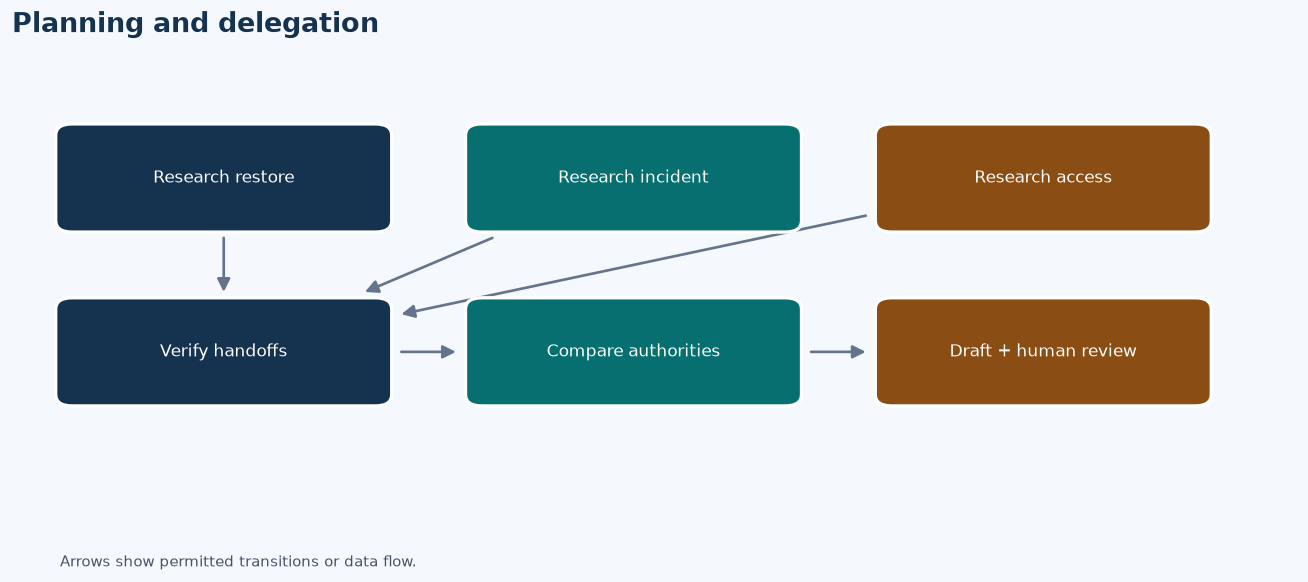

In [2]:
display(diagram('Planning and delegation', ['Research restore', 'Research incident', 'Research access', 'Verify handoffs', 'Compare authorities', 'Draft + human review'], [(0, 3), (1, 3), (2, 3), (3, 4), (4, 5)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
from deep_agent_lab.planning import PlanTask, complete_task, ready_tasks, SpecialistFinding, run_specialists
tasks = {"restore": PlanTask("restore", "Find restoration authority"),
         "incident": PlanTask("incident", "Find incident coordinator"),
         "compare": PlanTask("compare", "Compare authorities", {"restore", "incident"})}
assert {task.id for task in ready_tasks(tasks)} == {"restore", "incident"}
complete_task(tasks, "restore", {"BKP-7#p12"}, {"BKP-7#p12"})
assert "compare" not in {task.id for task in ready_tasks(tasks)}
complete_task(tasks, "incident", {"INC-3#p8"}, {"INC-3#p8"})
assert [task.id for task in ready_tasks(tasks)] == ["compare"]
finding = SpecialistFinding(question="Who approves?", claim="DB lead", evidence_ids=["BKP-7#p12"],
                            quotes=["Production restoration requires approval"], revisions=["4"],
                            status="proposed")
print(finding.model_dump())  # Proposed handoff; the parent still verifies IDs, quote and revision.

# From-scratch readiness is a dependency predicate, independent of model prose.
def ready_from_scratch(tasks):
    return [task.id for task in tasks.values() if task.status == "pending"
            and all(tasks[parent].status == "verified" for parent in task.dependencies)]
assert ready_from_scratch(tasks) == [task.id for task in ready_tasks(tasks)]

{'question': 'Who approves?', 'claim': 'DB lead', 'evidence_ids': ['BKP-7#p12'], 'quotes': ['Production restoration requires approval'], 'revisions': ['4'], 'status': 'proposed', 'unresolved': []}


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

In [4]:
from deep_agent_lab.labs import delegation_lab
delegation = await delegation_lab()  # Real task subagents dispatched through QuickJS Promise.all.
assert "database operations lead" in delegation["results"][1]
assert "incident commander" in delegation["results"][1]
print(delegation["results"][1])

C:\Users\imrah\Documents\deepagents\src\deep_agent_lab\labs.py:286: LangChainBetaWarning: The class `CodeInterpreterMiddleware` is in beta. It is actively being worked on, so the API may change.
  middleware=[TodoListMiddleware(), CodeInterpreterMiddleware(max_subagent_concurrency=2)],


<stdout>
["The database operations lead approves restores.","The incident commander coordinates the response."]
</stdout>
<result>null</result>


## Code walkthrough

The task graph has two independent research nodes and a dependent comparison. `complete_task` accepts only evidence present in the trusted registry. A todo label is coordination metadata and is insufficient for verification. The existing Deep Agents lab uses separate child contexts and real task tools; scripted child answers make its scheduling reproducible. `asyncio.Semaphore` is comparable to a concurrency limiter around Promise.all. Our dispatcher adds per-task timeouts, a total deadline and cancellation cleanup; it remains process-local.

## Interactive experiments

Change concurrency from one to two for independent I/O-bound tasks. Compare elapsed time while holding the simulated work constant. These timings demonstrate scheduling and are not model benchmarks.

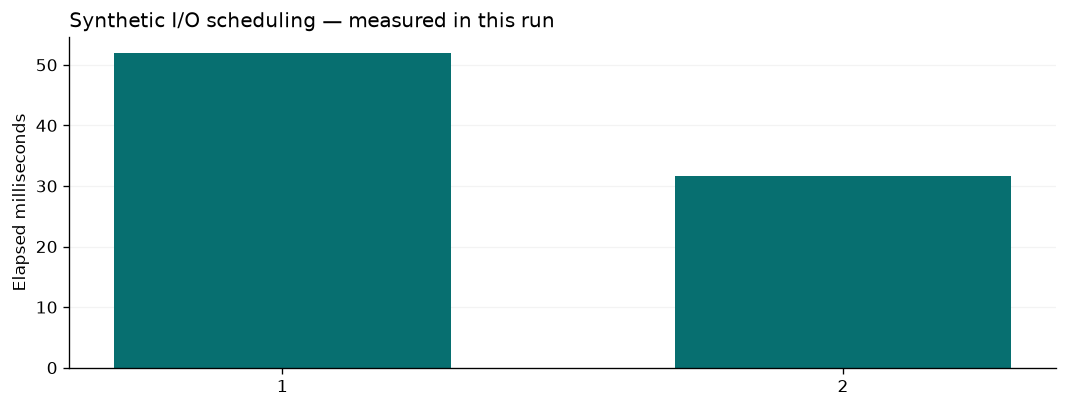

In [5]:
import asyncio, time
async def research(topic):
    await asyncio.sleep(0.02)
    return {"topic": topic, "evidence_ids": [topic]}
elapsed = {}
for concurrency in [1, 2]:
    started = time.perf_counter()
    findings = await run_specialists(["restore", "incident"], research, concurrency=concurrency)
    elapsed[str(concurrency)] = (time.perf_counter() - started) * 1000
    assert all(item["status"] == "success" for item in findings.values())
display(bars("Synthetic I/O scheduling", elapsed, ylabel="Elapsed milliseconds"))
plt.close("all")

## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
async def unreliable(topic):
    if topic == "incident":
        await asyncio.sleep(1)
    return {"evidence": topic}
partial = await run_specialists(["restore", "incident"], unreliable, timeout=0.005)
assert partial["restore"]["status"] == "success" and partial["incident"]["status"] == "timeout"
bad_plan = {"a": PlanTask("a", "cycle", {"b"}), "b": PlanTask("b", "cycle", {"a"})}
try:
    ready_tasks(bad_plan)
except ValueError as error:
    print("Expected dependency failure:", error)
else:
    raise AssertionError("Cycle accepted")

Expected dependency failure: Dependency cycle


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
assert tasks["compare"].status == "pending"
try:
    complete_task(tasks, "compare", {"invented"}, {"BKP-7#p12", "INC-3#p8"})
except ValueError:
    print("Expected: child assertions cannot verify nonexistent evidence.")
else:
    raise AssertionError("Unverified handoff accepted")

Expected: child assertions cannot verify nonexistent evidence.


## Exercise

Create a new plan for a partial-failure run. Verify only the restore task and show that comparison stays blocked until incident evidence is independently verified.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
partial_plan = {"restore": PlanTask("restore", "research"), "incident": PlanTask("incident", "research"),
                "compare": PlanTask("compare", "compare", {"restore", "incident"})}
complete_task(partial_plan, "restore", {"restore-source"}, {"restore-source"})
assert [task.id for task in ready_tasks(partial_plan)] == ["incident"]
assert partial_plan["compare"].status == "pending"

## Trade-offs and further reading

Delegation can isolate large contexts and shorten independent work. It also adds parent/child model calls and verification. For one short passage, direct RAG is usually the simpler baseline. Async execution alone cannot survive a process crash.

[Primary source 1](https://docs.langchain.com/oss/python/deepagents/subagents) · [Primary source 2](https://www.anthropic.com/engineering/multi-agent-research-system)

In [9]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
